In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/diabetes_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["readmitted_30_days"].value_counts())

print("\nUnique patients:", df["patient_nbr"].nunique())

Dataset shape: (101766, 52)

Target distribution:
readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64

Unique patients: 71518


In [2]:
# Inspect potential predictors for readmission modeling

candidate_features = [
    "age",
    "race",
    "gender",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "A1Cresult",
    "max_glu_serum",
    "diabetesMed"
]

print("Candidate features:", len(candidate_features))

print("\nFeature data types:")
print(df[candidate_features].dtypes)

print("\nMissing values:")
print(df[candidate_features].isna().sum())


Candidate features: 14

Feature data types:
age                     str
race                    str
gender                  str
time_in_hospital      int64
num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
number_diagnoses      int64
A1Cresult               str
max_glu_serum           str
diabetesMed             str
dtype: object

Missing values:
age                   0
race                  0
gender                0
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
number_diagnoses      0
A1Cresult             0
max_glu_serum         0
diabetesMed           0
dtype: int64


In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Select predictors and target
X = df[candidate_features].copy()
y = df["readmitted_30_days"]

# Keep encounters from the same patient together
groups = df["patient_nbr"]

# 80% training, 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Verify patient separation
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("Training encounters:", len(X_train))
print("Testing encounters:", len(X_test))

print("\nOverlapping patients:",
      len(train_patients.intersection(test_patients)))

print("\nTraining readmission rate:",
      round(y_train.mean() * 100, 2), "%")

print("Testing readmission rate:",
      round(y_test.mean() * 100, 2), "%")

Training encounters: 81613
Testing encounters: 20153

Overlapping patients: 0

Training readmission rate: 11.28 %
Testing readmission rate: 10.67 %


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")

Numerical features: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features: ['age', 'race', 'gender', 'A1Cresult', 'max_glu_serum', 'diabetesMed']

Preprocessing pipeline created successfully!


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and logistic regression
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train using only the training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict readmission outcomes
y_pred = model.predict(X_test)

# Predict probabilities of readmission
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluate model performance
print("Logistic Regression Model Performance")
print("-------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Model Performance
-------------------------------------
Accuracy: 0.8933
Precision: 0.5
Recall: 0.0088
F1-Score: 0.0174
ROC-AUC: 0.6278

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18002
           1       0.50      0.01      0.02      2151

    accuracy                           0.89     20153
   macro avg       0.70      0.50      0.48     20153
weighted avg       0.85      0.89      0.84     20153


Confusion Matrix:
[[17983    19]
 [ 2132    19]]


In [13]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import make_scorer, average_precision_score

# Create a balanced logistic regression pipeline
balanced_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Cross-validation keeps patients separated
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_results = cross_validate(
    balanced_model,
    X_train,
    y_train,
    groups=groups.iloc[train_idx],
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("Balanced Logistic Regression — Cross-Validation")
print("----------------------------------------------")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Balanced Logistic Regression — Cross-Validation
----------------------------------------------
recall: 0.4884 (+/- 0.0156)
precision: 0.1679 (+/- 0.0042)
f1: 0.2499 (+/- 0.0064)
roc_auc: 0.6330 (+/- 0.0090)
average_precision: 0.1944 (+/- 0.0085)


In [8]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

models = {
    "Original Logistic Regression": model,
    "Balanced Logistic Regression": balanced_model
}

comparison_results = []

for name, estimator in models.items():
    results = cross_validate(
        clone(estimator),
        X_train,
        y_train,
        groups=groups.iloc[train_idx],
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    comparison_results.append({
        "Model": name,
        "Recall": results["test_recall"].mean(),
        "Precision": results["test_precision"].mean(),
        "F1": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean(),
        "Average Precision": results["test_average_precision"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))

                       Model  Recall  Precision     F1  ROC-AUC  Average Precision
Original Logistic Regression  0.0165     0.4748 0.0319   0.6313             0.1943
Balanced Logistic Regression  0.4884     0.1679 0.2499   0.6330             0.1944


In [9]:
# Train balanced model on the full training dataset
balanced_model.fit(X_train, y_train)

# Make predictions on the held-out test set
y_pred_balanced = balanced_model.predict(X_test)

# Get predicted probabilities
y_prob_balanced = balanced_model.predict_proba(X_test)[:, 1]

# Evaluate final model
print("Final Balanced Logistic Regression Results")
print("------------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_balanced), 4))
print("Recall:", round(recall_score(y_test, y_pred_balanced), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_balanced), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_balanced), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Final Balanced Logistic Regression Results
------------------------------------------
Accuracy: 0.6743
Precision: 0.1573
Recall: 0.4709
F1-Score: 0.2359
ROC-AUC: 0.6281

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.70      0.79     18002
           1       0.16      0.47      0.24      2151

    accuracy                           0.67     20153
   macro avg       0.54      0.58      0.51     20153
weighted avg       0.84      0.67      0.73     20153


Confusion Matrix:
[[12576  5426]
 [ 1138  1013]]


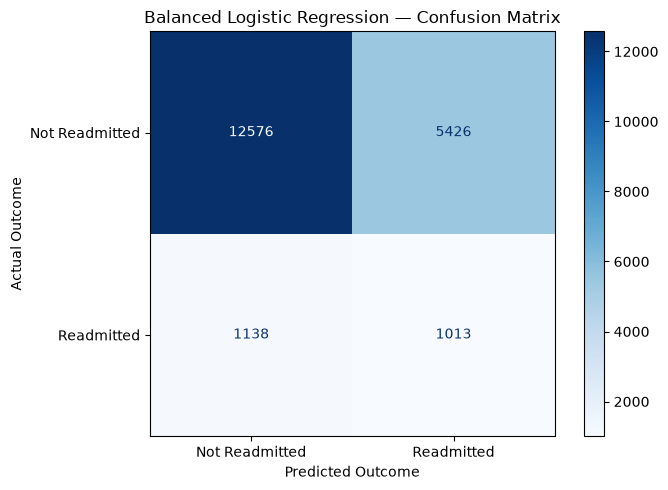

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Visualize final balanced model performance
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    display_labels=["Not Readmitted", "Readmitted"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Balanced Logistic Regression — Confusion Matrix")
ax.set_xlabel("Predicted Outcome")
ax.set_ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

In [11]:
# Get feature names after preprocessing
feature_names = balanced_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get logistic regression coefficients
coefficients = balanced_model.named_steps[
    "classifier"
].coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Top 15 Features by Coefficient Magnitude:")
print(feature_importance.head(15).to_string(index=False))

Top 15 Features by Coefficient Magnitude:
                        Feature  Coefficient  Absolute Coefficient
                cat__age_[0-10)    -1.492828              1.492828
          num__number_inpatient     0.373185              0.373185
               cat__age_[80-90)     0.294077              0.294077
               cat__age_[70-80)     0.287862              0.287862
              cat__age_[90-100)     0.280435              0.280435
               cat__age_[20-30)     0.227946              0.227946
               cat__age_[60-70)     0.227341              0.227341
               cat__age_[10-20)    -0.192518              0.192518
            cat__diabetesMed_No    -0.175624              0.175624
               cat__age_[30-40)     0.117622              0.117622
               cat__age_[40-50)     0.097515              0.097515
                cat__race_Asian    -0.096088              0.096088
cat__max_glu_serum_Not recorded    -0.091267              0.091267
          num__numbe

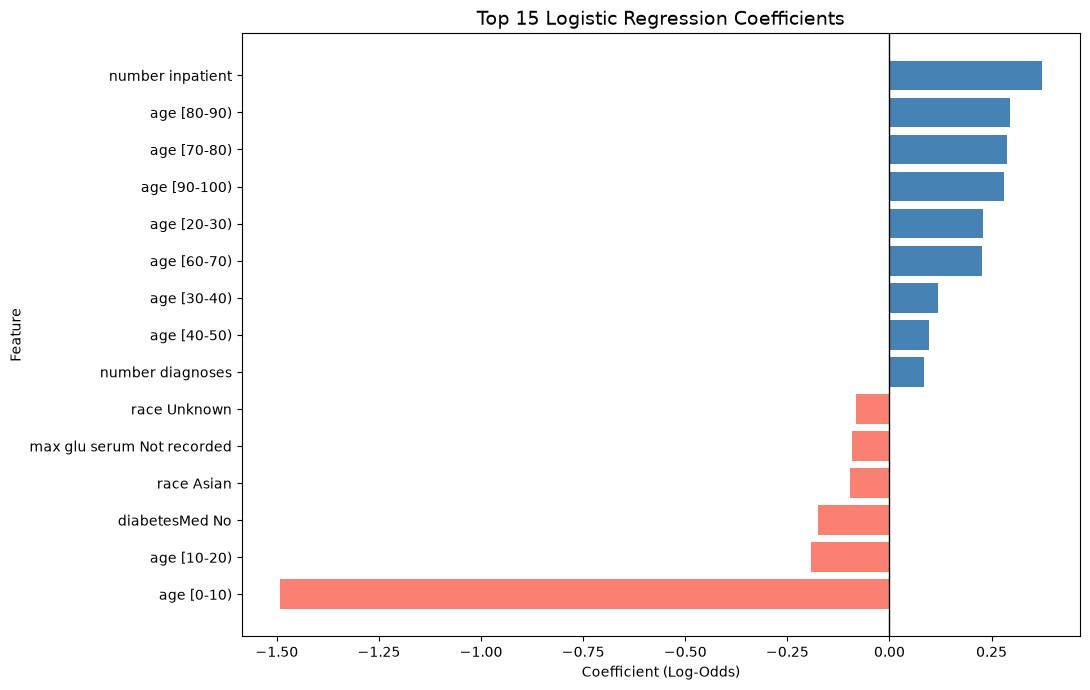

In [12]:
# Select the 15 largest coefficients by absolute magnitude
top_features = feature_importance.head(15).copy()

# Clean feature names for the chart
top_features["Feature Label"] = (
    top_features["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Sort for horizontal plotting
top_features = top_features.sort_values("Coefficient")

# Plot coefficients
plt.figure(figsize=(11, 7))

colors = [
    "steelblue" if value > 0 else "salmon"
    for value in top_features["Coefficient"]
]

plt.barh(
    top_features["Feature Label"],
    top_features["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Top 15 Logistic Regression Coefficients",
    fontsize=14
)

plt.xlabel("Coefficient (Log-Odds)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Model Interpretation and Key Findings

The balanced Logistic Regression model was developed to predict 30-day hospital readmissions using patient demographics, previous healthcare utilization, and hospital encounter characteristics.

**Key Findings**

1. **Previous inpatient visits:** The number of previous inpatient visits had a positive coefficient (0.3732), indicating an association with higher predicted readmission odds. This finding is consistent with the exploratory data analysis and SQL results, which showed higher observed readmission rates among patients with more previous hospitalizations.

2. **Age-related patterns:** Several age categories, including 70–80, 80–90, and 90–100, had positive coefficients. However, age coefficients should be interpreted cautiously because the categorical variables were one-hot encoded without a single reference category.

3. **Other clinical characteristics:** The number of diagnoses had a positive coefficient (0.0849), suggesting an association with increased predicted readmission odds. Not receiving diabetes medication had a negative coefficient (−0.1756).

**Model Performance**

The balanced Logistic Regression model achieved the following results on the held-out test set:

- Accuracy: 67.43%
- Precision: 15.73%
- Recall: 47.09%
- F1-score: 0.2359
- ROC-AUC: 0.6281

The model correctly identified 1,013 of 2,151 readmissions but also produced 5,426 false positives. Although class weighting improved recall substantially compared with the original Logistic Regression model, the low precision and modest ROC-AUC indicate limited predictive performance.

**Limitations**

- The dataset is historical, covering hospital encounters from 1999–2008.
- The dataset contains repeated encounters from some patients; patient-level splitting was used to prevent overlap between training and testing.
- The target class is imbalanced, with approximately 11% of encounters resulting in readmission within 30 days.
- Logistic Regression coefficients describe statistical associations, not causal relationships.
- Differences in feature encoding and scaling limit direct comparisons of coefficient magnitudes.
- The model has not undergone external validation, calibration assessment, or fairness evaluation and is not suitable for clinical decision-making.

**Conclusion**

Previous inpatient utilization emerged as an important predictor in both descriptive analysis and predictive modeling. While class weighting substantially improved the model's ability to identify readmissions, additional validation and model development would be necessary before considering practical healthcare applications.